# Week 3, Task 5: leaderboard and difference maps

Scores every baseline's `ssp245` predictions the same way, puts them next to the published leaderboard, and shows
prediction − truth maps for each model and target.

Run with the **jcm** kernel. The metric code is in `metrics.py`, which every baseline notebook also uses.

**Adding a model:** its notebook saves `results/<model>_ssp245.nc` with variables `tas`, `diurnal_temperature_range`,
`pr`, `pr90`; dims `(time, lat, lon)` on the ClimateBench grid; years 2015–2100; precipitation in mm/day.
This notebook picks up every such file in `results/`.

## The metrics

All over 2080–2100, against the `ssp245` ensemble mean, with area weights ∝ cos(latitude):

- **Spatial NRMSE:** average each field over 2080–2100 first, then take the area-weighted RMSE between the two maps.
  Measures how well the *pattern* is captured.
- **Global NRMSE:** take the area-weighted global mean each year, then the RMSE between the two yearly series.
  Measures the *global trajectory*.
- Both are divided by |global mean of the truth over 2080–2100|, so targets with different units are comparable.
- **Total = spatial + 5 × global.** The global term is usually much smaller than the spatial one, and the global-mean
  trajectory is what many uses care about most, so it is weighted up.

DTR's global-mean change is close to zero, so dividing by it makes DTR's NRMSE large for every model.
Compare models within a target, not across targets.

In [1]:
import os
import sys
from glob import glob

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

REPO = os.path.expanduser("~/DSC180-D06-JCM-Project")
sys.path.insert(0, REPO)
from metrics import TARGETS, PERIOD, load_ssp245, global_mean, nrmse, variability_floor

DATA = os.path.expanduser("~/data/climatebench")
FIGS = f"{REPO}/figures"
RESULTS = f"{REPO}/results"

STYLE = {"tas": ("tas", "K", "RdBu_r"),
         "diurnal_temperature_range": ("dtr", "K", "RdBu_r"),
         "pr": ("pr", "mm/day", "BrBG"),
         "pr90": ("pr90", "mm/day", "BrBG")}

members = load_ssp245(DATA)
truth = members.mean("member")

## Load every model's predictions

Each file is checked against the shared format before it is scored, so a wrong unit or grid fails loudly here
instead of quietly producing a bad score.

In [2]:
# file prefix -> display name, and the matching row of the published leaderboard
MODELS = {"pattern_scaling": ("Pattern scaling", None),
          "gp": ("Gaussian process", "Gaussian Process"),
          "rf": ("Random forest", "Random Forest"),
          "cnn_lstm": ("CNN-LSTM", "Neural Network")}


def check_format(ds, path):
    missing = [v for v in TARGETS if v not in ds]
    assert not missing, f"{path}: missing {missing}"
    for var in TARGETS:
        assert ds[var].dims == ("time", "lat", "lon"), f"{path}: {var} dims {ds[var].dims}"
    assert set(range(2080, 2101)) <= set(ds.time.values.tolist()), f"{path}: needs every year 2080-2100"
    assert np.allclose(ds.lat, truth.lat) and np.allclose(ds.lon, truth.lon), f"{path}: not on the ClimateBench grid"
    # mm/day check: global-mean precip change is O(0.1) mm/day; in kg m-2 s-1 it would be ~1e-6
    assert abs(float(global_mean(ds["pr"].sel(time=PERIOD)).mean())) > 1e-3, f"{path}: pr not in mm/day?"


preds = {}
for path in sorted(glob(f"{RESULTS}/*_ssp245.nc")):
    key = os.path.basename(path).removesuffix("_ssp245.nc")
    ds = xr.open_dataset(path)
    check_format(ds, path)
    preds[key] = ds
    print(f"loaded {key:16s} ({MODELS.get(key, (key,))[0]})")

missing = [MODELS[k][0] for k in MODELS if k not in preds]
print("not available yet:", ", ".join(missing) or "none")

loaded gp               (Gaussian process)
not available yet: Pattern scaling, Random forest, CNN-LSTM


## Leaderboard

Our models, the published scores from the ClimateBench README leaderboard (pattern scaling is not in the README; its
published row is in the paper's results table), and a rough internal-variability floor.

**Variability floor:** the truth is a 3-member mean, so it still contains weather noise that no emulator of the forced
response can predict. Each `ssp245` member is scored against the mean of the other two; if members are independent with equal
noise, a *perfect* emulator would score about 0.47× that against the 3-member mean. Treat it as the order of magnitude of the
best achievable NRMSE (Question 3).

In [3]:
# README leaderboard, github.com/duncanwp/ClimateBench
PUBLISHED = {
    "Neural Network": {
        "tas": (0.107294, 0.0440271, 0.327429), "diurnal_temperature_range": (9.91735, 1.37219, 16.7783),
        "pr": (2.1281, 0.2093, 3.1746), "pr90": (2.61022, 0.345709, 4.33876)},
    "Gaussian Process": {
        "tas": (0.109106, 0.0738238, 0.478225), "diurnal_temperature_range": (9.20713, 2.67495, 22.5819),
        "pr": (2.34092, 0.341453, 4.04818), "pr90": (2.5559, 0.429154, 4.70167)},
    "Random Forest": {
        "tas": (0.107574, 0.0584057, 0.399602), "diurnal_temperature_range": (9.19503, 2.65241, 22.4571),
        "pr": (2.52431, 0.502126, 5.03494), "pr90": (2.68209, 0.543375, 5.39896)},
}
METRICS = ["Spatial", "Global", "Total"]


def to_row(scores):
    return pd.Series({(STYLE[var][0], k): scores[var][k] for var in TARGETS for k in METRICS})


rows = {}
for key, ds in preds.items():
    name, published_name = MODELS.get(key, (key, None))
    rows[f"{name} (ours)"] = to_row({var: nrmse(truth[var], ds[var]) for var in TARGETS})
    if published_name:
        rows[f"{name} (published)"] = to_row({var: dict(zip(METRICS, PUBLISHED[published_name][var]))
                                              for var in TARGETS})
rows["Variability floor (approx.)"] = to_row({var: variability_floor(members[var]) for var in TARGETS})

leaderboard = pd.DataFrame(rows).T
leaderboard.to_csv(f"{RESULTS}/leaderboard.csv")
leaderboard.round(3)

tas                   dtr                 \
                             Spatial Global  Total Spatial Global   Total   
Gaussian process (ours)        0.090  0.042  0.299   8.560  2.391  20.517   
Gaussian process (published)   0.109  0.074  0.478   9.207  2.675  22.582   
Variability floor (approx.)    0.049  0.037  0.235   2.820  0.862   7.130   

                                  pr                  pr90                
                             Spatial Global  Total Spatial Global  Total  
Gaussian process (ours)        2.225  0.337  3.909   2.632  0.404  4.652  
Gaussian process (published)   2.341  0.341  4.048   2.556  0.429  4.702  
Variability floor (approx.)    1.453  0.138  2.142   1.827  0.236  3.009

**Ours ÷ published** for each model we have (below 1 = we score better). If a model is clearly *better* than the
published one, check for leakage from `ssp245` before believing it.

In [4]:
ratios = {}
for key in preds:
    name, published_name = MODELS.get(key, (key, None))
    if published_name:
        ratios[name] = leaderboard.loc[f"{name} (ours)"] / leaderboard.loc[f"{name} (published)"]
pd.DataFrame(ratios).T.round(2)

tas                  dtr                   pr         \
                 Spatial Global Total Spatial Global Total Spatial Global   
Gaussian process    0.83   0.57  0.63    0.93   0.89  0.91    0.95   0.99   

                          pr90               
                 Total Spatial Global Total  
Gaussian process  0.97    1.03   0.94  0.99

## Difference maps: prediction − truth, 2080–2100 mean

One row per target, one column per model. Each row shares a colour scale, so models can be compared directly.

/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-pac

/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-pac

/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-pac

/Users/romanrespicio/miniforge3/envs/jcm/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


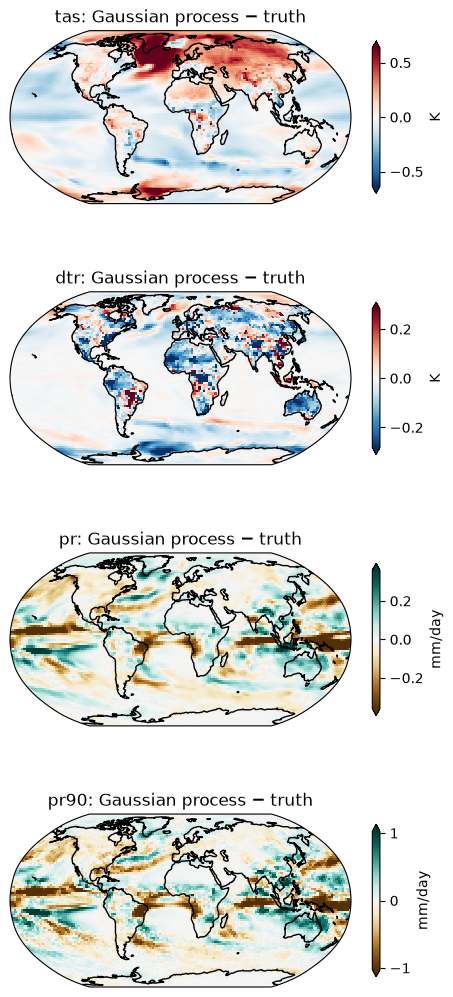

In [5]:
keys = list(preds)
fig, axes = plt.subplots(len(TARGETS), len(keys), figsize=(5.5 * len(keys), 13),
                         subplot_kw={"projection": ccrs.Robinson()}, squeeze=False)
for row, var in enumerate(TARGETS):
    name, unit, cmap = STYLE[var]
    t = truth[var].sel(time=PERIOD).mean("time")
    diffs = {k: preds[k][var].sel(time=PERIOD).mean("time") - t for k in keys}
    lim = max(float(np.nanpercentile(np.abs(d), 98)) for d in diffs.values())
    for ax, k in zip(axes[row], keys):
        diffs[k].plot(ax=ax, transform=ccrs.PlateCarree(), cmap=cmap, vmin=-lim, vmax=lim,
                      cbar_kwargs={"label": unit, "shrink": 0.7})
        ax.coastlines()
        ax.set_title(f"{name}: {MODELS.get(k, (k,))[0]} − truth")
fig.savefig(f"{FIGS}/week3_difference_maps.png", dpi=150, bbox_inches="tight")

## Global-mean trajectories

What the global NRMSE measures: each model's yearly global mean against the `ssp245` members and their mean.
The spread of the gray member lines is internal variability.

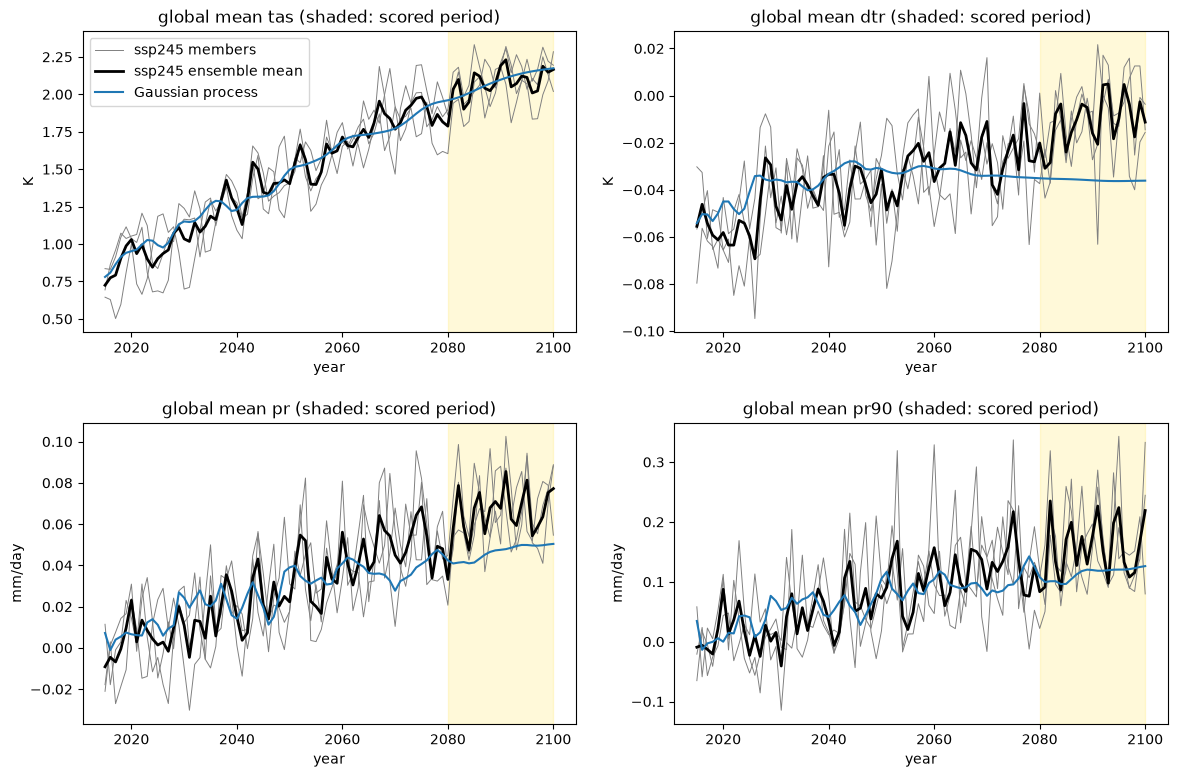

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), gridspec_kw={"hspace": 0.3})
for ax, var in zip(axes.flat, TARGETS):
    name, unit, _ = STYLE[var]
    for i, m in enumerate(members.member.values):
        ax.plot(truth.time, global_mean(members[var].sel(member=m)), color="gray", lw=0.7,
                label="ssp245 members" if i == 0 else None)
    ax.plot(truth.time, global_mean(truth[var]), color="black", lw=2, label="ssp245 ensemble mean")
    for k, ds in preds.items():
        ax.plot(ds.time, global_mean(ds[var]), label=MODELS.get(k, (k,))[0])
    ax.axvspan(PERIOD.start, PERIOD.stop, color="gold", alpha=0.15)
    ax.set_title(f"global mean {name} (shaded: scored period)")
    ax.set_xlabel("year")
    ax.set_ylabel(unit)
axes[0, 0].legend()
fig.savefig(f"{FIGS}/week3_global_means.png", dpi=150, bbox_inches="tight")

## Notes for the write-up

- For each model and target: reproduced or not, and the most likely cause (Question 1).
- Which target is hardest, and why (Question 2).
- How our errors compare with the variability floor (Question 3).